# Fase D – Analisi inter-layer (RQ2)

**RQ2: gli attori influenti conservano importanza e relazioni nei diversi layer?**

Segue le priorità alte e medie della fase D del piano: overlap dei nodi, top-actor overlap, rank correlation, community overlap, confronto delle partizioni, edge overlap. Le analisi avanzate del piano (multilayer community detection, link prediction) sono facoltative e non sono incluse. Richiede `fase_b_reti.ipynb` e `fase_c_intra_layer.ipynb`.

**Due baseline per le sovrapposizioni** (*random attribute model* della lezione 8: la struttura dei layer resta fissa, cambia chi è chi):
* **A – identità casuali nel layer**: il top-k di un layer è un sottoinsieme casuale dei wallet di quel layer;
* **B – solo tra i wallet condivisi**: stessa cosa, ma condizionata al fatto di essere presenti in entrambi i layer. È la più severa, perché toglie l'effetto "chi è attivo ovunque".

Sono distribuzioni ipergeometriche, quindi media e deviazione standard si calcolano esattamente.

## 0. Dati

In [1]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy import stats
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from analisi_utils import *

stile()
N_NULL = 50
N_PERM = 200
TOP_Q = 0.01                         # influente = nel top 1% per forza dei wallet con archi del layer
K_LISTA = [10, 20, 50, 100, 200, 500, 1000, 2000, 5000, 10000]
Q_LISTA = [0.001, 0.005, 0.01, 0.05, 0.10]
TOP_MAPPA = 15                       # comunità mostrate nella heatmap
PRINCIPALE = 'senza_contratti'
A, B = LAYERS                        # per i gift basterà ripetere le analisi su ogni coppia di layer

rampa_cross = LinearSegmentedColormap.from_list('cross', ['#e7f6f0', '#1baf7a', '#0b5c40'])
blu_rosso = LinearSegmentedColormap.from_list('bluerosso', ['#2a78d6', '#f0efec', '#e34948'])
CENTR = {v: pd.read_parquet(cartella_variante(v) / 'centralita.parquet') for v in VARIANTI}
WL = {v: pd.read_parquet(cartella_variante(v) / 'wallet_layer.parquet') for v in VARIANTI}

def serie(variante, metrica, layer, solo_attivi=True):
    c = CENTR[variante]
    c = c[c.layer == layer]
    if solo_attivi:
        c = c[c.grado > 0]
    return c.set_index('wallet')[metrica]

## 1. Overlap dei nodi

Un wallet è presente in un layer se ha posseduto almeno un NFT di quel mercato. Quanto pesano i wallet condivisi si vede dalla quota di eventi che generano.

versione,senza contratti,completa
solo username,311.831,520.584
solo numeri,99.053,114.650
in entrambi,34.302,34.381
Jaccard,0.0771,0.0513
con archi in entrambi,30.532,30.616
condivisi su username,0.0991,0.062
condivisi su numeri,0.257,0.231
eventi username dei condivisi,0.324,0.28
eventi numeri dei condivisi,0.572,0.564


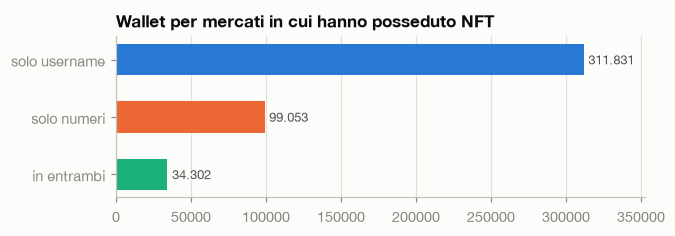

In [2]:
righe = []
for v in VARIANTI:
    w = WL[v]
    pa, pb = set(w[w.layer == A].wallet), set(w[w.layer == B].wallet)
    aa, ab = set(serie(v, 'forza', A).index), set(serie(v, 'forza', B).index)
    comuni = pa & pb
    eventi = w.assign(condiviso=w.wallet.isin(comuni)).groupby(['layer', 'condiviso']).n_eventi.sum()
    righe.append({'versione': NOME_VARIANTE[v], f'solo {NOME[A].lower()}': len(pa - pb), f'solo {NOME[B].lower()}': len(pb - pa), 'in entrambi': len(comuni),
                  'Jaccard': len(comuni) / len(pa | pb), 'con archi in entrambi': len(aa & ab),
                  f'condivisi su {NOME[A].lower()}': len(comuni) / len(pa), f'condivisi su {NOME[B].lower()}': len(comuni) / len(pb),
                  f'eventi {NOME[A].lower()} dei condivisi': eventi[A, True] / eventi[A].sum(), f'eventi {NOME[B].lower()} dei condivisi': eventi[B, True] / eventi[B].sum()})
tab = pd.DataFrame(righe).set_index('versione')
salva_tabella(tab, 'd_overlap_nodi')
display(leggibile(tab.T))

r = tab.loc[NOME_VARIANTE[PRINCIPALE]]
nomi = [f'solo {NOME[A].lower()}', f'solo {NOME[B].lower()}', 'in entrambi']
valori = [r[n] for n in nomi]
fig, ax = plt.subplots(figsize=(6.2, 1.9))
ax.barh(range(3), valori, height=0.55, color=[COLORI[A], COLORI[B], COLORI['cross']])
for i, x in enumerate(valori):
    ax.text(x + max(valori) * 0.01, i, f'{int(x):,}'.replace(',', '.'), va='center', fontsize=8.5, color=SECONDARIO)
ax.set_yticks(range(3), nomi)
ax.invert_yaxis()
ax.grid(axis='y', visible=False)
ax.set_xlim(right=max(valori) * 1.13)
ax.set_title('Wallet per mercati in cui hanno posseduto NFT')
salva_figura(fig, 'd_overlap_nodi')
plt.show()

## 2. Top-actor overlap

Per grado, forza e PageRank: quanti dei k wallet più importanti di un layer lo sono anche nell'altro. Il grafico mostra la quota sui k, con le due baseline; la tabella salvata ha anche il Jaccard e gli z-score, per entrambe le versioni della rete.

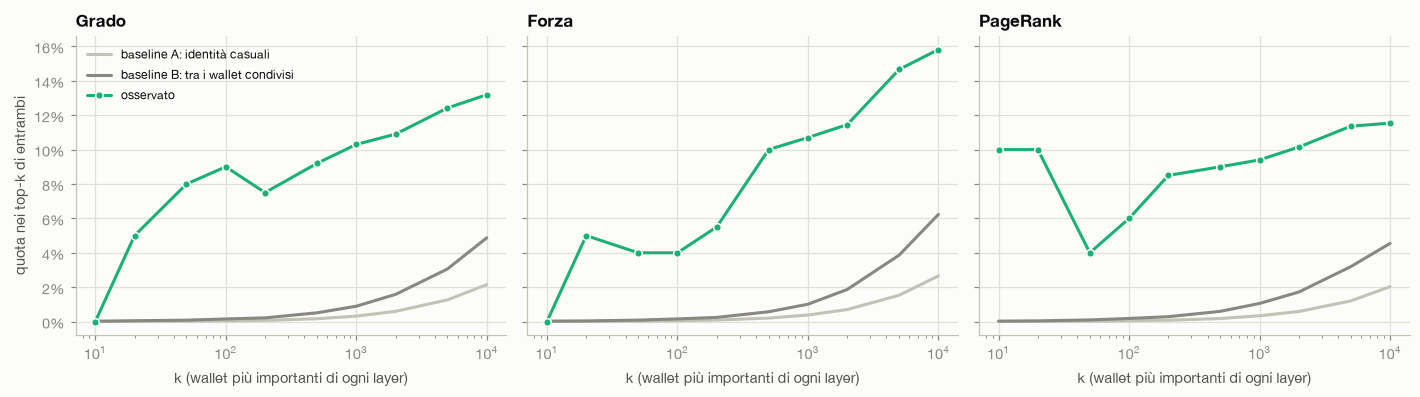

k layer A  k layer B  in entrambi  Jaccard  attesi A   z A  attesi B   z B
versione        valore                                                                            
senza contratti 0.001         317        124           14  0.03279    0.1634 34.27    0.4942 19.29
                0.005        1583        622          107    0.051     3.554 55.17     9.478 32.27
                0.01         3166       1244          234  0.05603     12.86 62.31     34.24 35.35
                0.05        15832       6222         1547  0.07544     233.8 89.83     579.1 46.69
                0.1         31664      12444         3150  0.07691     758.7 94.43      1714 45.49
completa        0.001         526        140           29  0.04553    0.2658 55.82    0.8949 29.89
                0.005        2628        701          146  0.04587     5.538 60.07     16.63 32.56
                0.01         5255       1401          321  0.05067     19.69 68.73     59.04 35.79
                0.05        26275       7006         1841  0.05856     279.4 97.83     762.6 46.48
                0.1         52550      14012         3842  0.06126     893.3 107.5      2229 46.87

In [3]:
def ipergeometrica(pop, successi, estratti):
    d = stats.hypergeom(pop, successi, estratti)
    return d.mean(), d.std()

def confronta(sa, sb, ka, kb):
    ta, tb = set(sa.nlargest(ka).index), set(sb.nlargest(kb).index)
    comuni = sa.index.intersection(sb.index)
    inter = len(ta & tb)
    m_a, s_a = ipergeometrica(len(sb), len(ta & set(sb.index)), kb)
    m_b, s_b = ipergeometrica(len(comuni), len(ta & set(comuni)), len(tb & set(comuni)))
    return {'in entrambi': inter, 'Jaccard': inter / len(ta | tb), 'attesi A': m_a, 'z A': (inter - m_a) / s_a if s_a > 0 else np.nan,
            'attesi B': m_b, 'z B': (inter - m_b) / s_b if s_b > 0 else np.nan}

righe = []
for v in VARIANTI:
    for metrica in ['grado', 'forza', 'pagerank']:
        sa, sb = serie(v, metrica, A), serie(v, metrica, B)
        for k in K_LISTA:
            righe.append({'versione': NOME_VARIANTE[v], 'metrica': metrica, 'soglia': 'k', 'valore': k, 'k layer A': k, 'k layer B': k, **confronta(sa, sb, k, k)})
        for q in Q_LISTA:
            ka, kb = int(round(q * len(sa))), int(round(q * len(sb)))
            righe.append({'versione': NOME_VARIANTE[v], 'metrica': metrica, 'soglia': 'quota', 'valore': q, 'k layer A': ka, 'k layer B': kb, **confronta(sa, sb, ka, kb)})
TOP = pd.DataFrame(righe)
salva_tabella(TOP, 'd_top_actor_overlap', index=False)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.7), sharey=True)
for ax, metrica in zip(axes, ['grado', 'forza', 'pagerank']):
    t = TOP[(TOP.versione == NOME_VARIANTE[PRINCIPALE]) & (TOP.metrica == metrica) & (TOP.soglia == 'k')]
    ax.plot(t.valore, t['attesi A'] / t.valore, color='#c3c2b7', label='baseline A: identità casuali')
    ax.plot(t.valore, t['attesi B'] / t.valore, color=GRIGIO, label='baseline B: tra i wallet condivisi')
    ax.plot(t.valore, t['in entrambi'] / t.valore, color=COLORI['cross'], marker='o', markersize=5, markeredgecolor=SUPERFICIE, label='osservato')
    ax.set_xscale('log')
    ax.set_title({'grado': 'Grado', 'forza': 'Forza', 'pagerank': 'PageRank'}[metrica])
    ax.set_xlabel('k (wallet più importanti di ogni layer)')
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
axes[0].set_ylabel('quota nei top-k di entrambi')
axes[0].legend(fontsize=8)
fig.tight_layout()
salva_figura(fig, 'd_top_actor_overlap')
plt.show()
t = TOP[(TOP.metrica == 'forza') & (TOP.soglia == 'quota')].set_index(['versione', 'valore'])[['k layer A', 'k layer B', 'in entrambi', 'Jaccard', 'attesi A', 'z A', 'attesi B', 'z B']]
t

## 3. Rank correlation

Spearman sui wallet presenti in entrambi i layer, con il numero di wallet e l'intervallo di confidenza al 95% (bootstrap sui wallet). Due insiemi: tutti i wallet condivisi, e solo quelli con archi in entrambi. Il risultato dice se, tra chi opera in entrambi, chi conta in un mercato conta anche nell'altro.

n    rho  IC 2,5%  IC 97,5%
versione        metrica  insieme                                               
senza contratti grado    tutti i condivisi      34302 0.3649   0.3564    0.3744
                         con archi in entrambi  30532  0.373   0.3635     0.381
                forza    tutti i condivisi      34302 0.3619   0.3528    0.3714
                         con archi in entrambi  30532 0.3471    0.338    0.3565
                pagerank tutti i condivisi      34302 0.4284   0.4186    0.4371
                         con archi in entrambi  30532 0.3832   0.3724    0.3923
completa        grado    tutti i condivisi      34381 0.3672   0.3569    0.3768
                         con archi in entrambi  30616 0.3754   0.3643    0.3864
                forza    tutti i condivisi      34381 0.3633   0.3545    0.3732
                         con archi in entrambi  30616 0.3486   0.3386    0.3587
                pagerank tutti i condivisi      34381 0.4294   0.4202    0.4385
                         con archi in entrambi  30616 0.3849   0.3758    0.3942

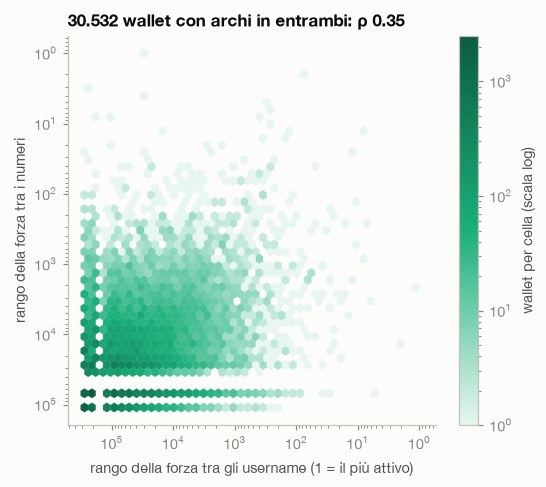

In [4]:
def spearman_ic(x, y, n_boot=N_PERM, seed=SEED):
    rng = np.random.default_rng(seed)
    x, y = stats.rankdata(x), stats.rankdata(y)
    rho = np.corrcoef(x, y)[0, 1]
    boot = [np.corrcoef(x[i], y[i])[0, 1] for i in (rng.integers(0, len(x), len(x)) for _ in range(n_boot))]
    return rho, *np.percentile(boot, [2.5, 97.5])

righe = []
for v in VARIANTI:
    for metrica in ['grado', 'forza', 'pagerank']:
        for insieme, solo in [('tutti i condivisi', False), ('con archi in entrambi', True)]:
            sa, sb = serie(v, metrica, A, solo), serie(v, metrica, B, solo)
            comuni = sa.index.intersection(sb.index)
            rho, lo, hi = spearman_ic(sa[comuni].to_numpy(), sb[comuni].to_numpy())
            righe.append({'versione': NOME_VARIANTE[v], 'metrica': metrica, 'insieme': insieme, 'n': len(comuni), 'rho': rho, 'IC 2,5%': lo, 'IC 97,5%': hi})
RHO = pd.DataFrame(righe).set_index(['versione', 'metrica', 'insieme'])
salva_tabella(RHO, 'd_rank_correlation')
display(RHO)

sa, sb = serie(PRINCIPALE, 'forza', A), serie(PRINCIPALE, 'forza', B)
comuni = sa.index.intersection(sb.index)
ra, rb = sa.rank(ascending=False)[comuni], sb.rank(ascending=False)[comuni]
fig, ax = plt.subplots(figsize=(5.4, 4.6))
hb = ax.hexbin(ra, rb, gridsize=45, xscale='log', yscale='log', bins='log', cmap=rampa_cross, mincnt=1, linewidths=0.2)
ax.invert_xaxis(); ax.invert_yaxis()
ax.grid(False)
fig.colorbar(hb, ax=ax, label='wallet per cella (scala log)')
ax.set_xlabel(f'rango della forza tra gli {NOME[A].lower()} (1 = il più attivo)')
ax.set_ylabel(f'rango della forza tra i {NOME[B].lower()}')
ax.set_title(f'{len(comuni):,} wallet con archi in entrambi: ρ {RHO.loc[(NOME_VARIANTE[PRINCIPALE], "forza", "con archi in entrambi"), "rho"]:.2f}'.replace(',', '.'))
salva_figura(fig, 'd_rank_correlation')
plt.show()

## 4. Core cross-layer

**Core**: wallet nel top `TOP_Q` per forza in almeno due layer. Il **coefficiente di partecipazione** mostra come ogni wallet divide la propria attività: P = 0 tutta in un layer, P = 1 divisa in parti uguali.

top 1%: 3166 wallet in username, 1244 in numeri | core: 234 | specialisti influenti: 2932 e 1010
forza minima per entrare nel top: 101 136
wallet per fascia di P: {'focalizzati (P < 0,3)': 383719, 'multiplex (P > 0,6)': 21062, 'misti': 5764}
quota del core sui passaggi: Username 4.9%, Numeri 13.8%


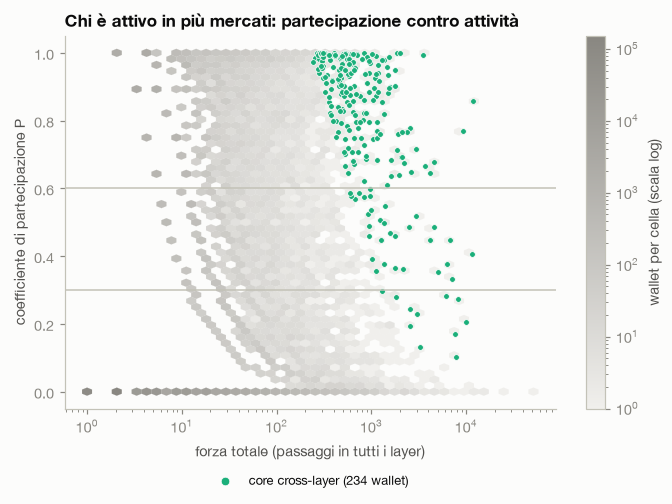

In [5]:
sa, sb = serie(PRINCIPALE, 'forza', A), serie(PRINCIPALE, 'forza', B)
ka, kb = int(round(TOP_Q * len(sa))), int(round(TOP_Q * len(sb)))
INF = {A: set(sa.nlargest(ka).index), B: set(sb.nlargest(kb).index)}
core = INF[A] & INF[B]
pd.Series(sorted(core), name='wallet').to_frame().to_parquet(cartella_variante(PRINCIPALE) / 'core.parquet')

F = pd.DataFrame({A: sa, B: sb}).fillna(0)
o = F.sum(axis=1)
M = len(LAYERS)
P = M / (M - 1) * (1 - (F.div(o, axis=0) ** 2).sum(axis=1))
fasce = pd.cut(P, [-0.01, 0.3, 0.6, 1.0], labels=['focalizzati (P < 0,3)', 'misti', 'multiplex (P > 0,6)']).value_counts()
print(f'top {TOP_Q:.0%}: {ka} wallet in {NOME[A].lower()}, {kb} in {NOME[B].lower()} | core: {len(core)} | specialisti influenti: {ka - len(core)} e {kb - len(core)}')
print('forza minima per entrare nel top:', int(sa.nlargest(ka).min()), int(sb.nlargest(kb).min()))
print('wallet per fascia di P:', fasce.to_dict())
print(f'quota del core sui passaggi: {NOME[A]} {sa[list(core)].sum() / sa.sum():.1%}, {NOME[B]} {sb[list(core)].sum() / sb.sum():.1%}')

fig, ax = plt.subplots(figsize=(7.2, 4.4))
hb = ax.hexbin(o[o > 0], P[o > 0], gridsize=(45, 28), xscale='log', bins='log', cmap=LinearSegmentedColormap.from_list('g', ['#f0efec', '#898781']), mincnt=1, linewidths=0.1)
c = list(core)
ax.scatter(o[c], P[c], s=14, color=COLORI['cross'], edgecolors=SUPERFICIE, linewidths=0.5, label=f'core cross-layer ({len(core)} wallet)')
for soglia in (0.3, 0.6):
    ax.axhline(soglia, color='#c3c2b7', linewidth=1)
ax.grid(False)
fig.colorbar(hb, ax=ax, label='wallet per cella (scala log)')
ax.set_xlabel('forza totale (passaggi in tutti i layer)')
ax.set_ylabel('coefficiente di partecipazione P')
ax.set_title('Chi è attivo in più mercati: partecipazione contro attività')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.14), fontsize=8.5, markerscale=1.5)
salva_figura(fig, 'd_partecipazione')
plt.show()

## 5. Community overlap

Le comunità sono quelle calcolate **separatamente** in ogni layer (fase C), quindi questa non è una multilayer community detection. Per ogni coppia U_i–N_j, sui wallet con archi in entrambi i layer:
* intersezione e Jaccard (sulle comunità intere);
* percentuali direzionali: quota dei wallet condivisi di U_i in N_j e viceversa;
* **lift** = intersezione osservata / attesa dati i wallet condivisi delle due comunità: normalizza per la dimensione. La heatmap mostra il log2 con un punto dove q < 0,01.

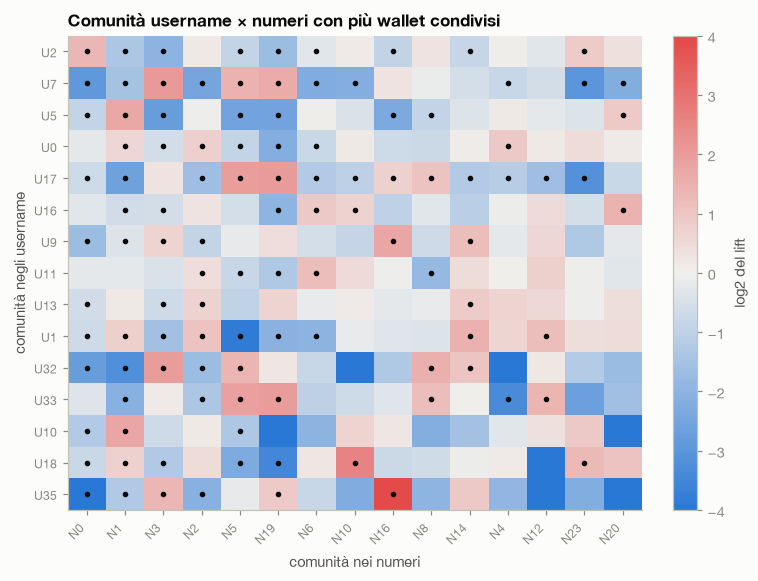

wallet con archi in entrambi: 30532 | coppie di comunità con wallet in comune: 4611 | con q < 0,01 e lift > 2: 2452


,U,N,inter,attesi,lift,z,% di U in N,% di N in U,Jaccard,q
53895,127,84,39,0.04982,782.9,174.7,1,1,1,0
61808,160,32,23,0.1567,146.8,57.93,1,0.1106,0.03348,0
20178,43,57,22,0.2175,101.1,46.84,0.4074,0.1789,0.02426,0
45418,104,22,40,0.5294,75.55,54.56,0.7547,0.1311,0.0274,0
39327,87,15,22,0.3091,71.17,39.26,0.8462,0.06061,0.01068,0
31845,70,21,60,1.245,48.2,53.06,0.5714,0.1657,0.03519,0
29993,66,43,28,0.6016,46.54,35.48,0.2393,0.1783,0.03402,2.11e-274
52894,125,10,41,1.131,36.26,38.05,1,0.04869,0.01562,0
57102,139,6,30,0.9079,33.04,31.02,1,0.03247,0.009186,6.102e-210
22496,48,32,21,1.083,19.39,19.25,0.1321,0.101,0.01639,1.708e-81


In [6]:
comu = {l: pd.read_parquet(cartella_variante(PRINCIPALE) / f'comunita_{FILE[l]}.parquet').set_index('wallet').comunita for l in LAYERS}
S = comu[A].index.intersection(comu[B].index)
ca, cb = comu[A][S], comu[B][S]
incr = pd.crosstab(ca.to_numpy(), cb.to_numpy())
na, nb, n = incr.sum(axis=1), incr.sum(axis=0), len(S)
dim_a, dim_b = comu[A].value_counts(), comu[B].value_counts()

lunga = incr.stack().rename('inter').rename_axis(['U', 'N']).reset_index()
lunga = lunga[lunga.inter > 0]
lunga['condivisi_U'] = lunga.U.map(na); lunga['condivisi_N'] = lunga.N.map(nb)
lunga['attesi'] = lunga.condivisi_U * lunga.condivisi_N / n
lunga['lift'] = lunga.inter / lunga.attesi
var = lunga.attesi * (1 - lunga.condivisi_N / n) * (n - lunga.condivisi_U) / (n - 1)
lunga['z'] = (lunga.inter - lunga.attesi) / np.sqrt(var)
lunga['% di U in N'] = lunga.inter / lunga.condivisi_U
lunga['% di N in U'] = lunga.inter / lunga.condivisi_N
lunga['Jaccard'] = lunga.inter / (lunga.U.map(dim_a) + lunga.N.map(dim_b) - lunga.inter)
lunga['q'] = benjamini_hochberg(2 * stats.norm.sf(np.abs(lunga.z.fillna(0))))
salva_tabella(lunga.sort_values('inter', ascending=False).head(5000), 'd_community_overlap', index=False)

su = na.sort_values(ascending=False).index[:TOP_MAPPA]
sv = nb.sort_values(ascending=False).index[:TOP_MAPPA]
mat = np.log2((incr.loc[su, sv] / (np.outer(na[su], nb[sv]) / n)).replace(0, np.nan))
fig, ax = plt.subplots(figsize=(7.4, 5.6))
im = ax.imshow(mat.clip(-4, 4).fillna(-4), vmin=-4, vmax=4, cmap=blu_rosso, aspect='auto')
sig = lunga[(lunga.q < 0.01) & lunga.U.isin(su) & lunga.N.isin(sv)]
ax.scatter(pd.Index(sv).get_indexer(sig.N), pd.Index(su).get_indexer(sig.U), s=7, color=INK)
ax.set_xticks(range(TOP_MAPPA), [f'N{i}' for i in sv], rotation=45, ha='right', fontsize=8)
ax.set_yticks(range(TOP_MAPPA), [f'U{i}' for i in su], fontsize=8)
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.04, label='log2 del lift')
ax.set_title('Comunità username × numeri con più wallet condivisi')
ax.set_xlabel('comunità nei numeri'); ax.set_ylabel('comunità negli username')
salva_figura(fig, 'd_community_overlap')
plt.show()

print(f'wallet con archi in entrambi: {n} | coppie di comunità con wallet in comune: {len(lunga)} | con q < 0,01 e lift > 2: {((lunga.q < 0.01) & (lunga.lift > 2)).sum()}')
lunga[lunga.inter >= 20].sort_values('lift', ascending=False).head(12)[['U', 'N', 'inter', 'attesi', 'lift', 'z', '% di U in N', '% di N in U', 'Jaccard', 'q']]

## 6. Confronto delle partizioni

ARI e NMI **solo sullo stesso insieme** di wallet (con archi in entrambi). Nullo: si rimescolano le etichette di comunità di un layer tra questi wallet.

In [7]:
xa, xb = ca.to_numpy(), cb.to_numpy()
oss = {'ARI': adjusted_rand_score(xa, xb), 'NMI': normalized_mutual_info_score(xa, xb)}
rng = np.random.default_rng(SEED)
nullo = pd.DataFrame([{'ARI': adjusted_rand_score(xa, p), 'NMI': normalized_mutual_info_score(xa, p)} for p in (rng.permutation(xb) for _ in range(N_PERM))])
tab = pd.DataFrame({m: {'wallet': n, 'osservato': oss[m], 'media nullo': nullo[m].mean(), 'z': z_score(oss[m], nullo[m]), 'p empirico': p_empirico(oss[m], nullo[m])} for m in oss}).T
salva_tabella(tab, 'd_confronto_partizioni')
tab

,wallet,osservato,media nullo,z,p empirico
ARI,3.053e+04,0.09279,3.912e-05,130.4,0.004975
NMI,3.053e+04,0.2706,0.1321,149.8,0.004975


## 7. Edge overlap

Stesse coppie di wallet in entrambi i layer: senza direzione, con la stessa direzione, con direzione opposta; partner condivisi dei wallet comuni. Nullo: **configuration model su ogni layer**, rimescolati in modo indipendente. La stessa misura solo sulle vendite dice se i legami condivisi sono scambi di mercato o trasferimenti senza prezzo.

In [8]:
def indice_globale(archi_a, archi_b):
    return pd.Index(pd.unique(np.concatenate([archi_a.sender, archi_a.recipient, archi_b.sender, archi_b.recipient])))

def overlap_archi(aa, ab, indice):
    N = len(indice)
    sa_, ra_ = indice.get_indexer(aa.sender), indice.get_indexer(aa.recipient)
    sb_, rb_ = indice.get_indexer(ab.sender), indice.get_indexer(ab.recipient)
    dir_a, dir_b, inv_b = sa_ * N + ra_, sb_ * N + rb_, rb_ * N + sb_
    und_a = np.unique(np.minimum(sa_, ra_) * N + np.maximum(sa_, ra_))
    und_b = np.unique(np.minimum(sb_, rb_) * N + np.maximum(sb_, rb_))
    # partner condivisi: matrici di adiacenza non orientate, sui wallet con archi in entrambi
    def adiacenza(s, r):
        m = sp.coo_matrix((np.ones(2 * len(s), dtype=np.int8), (np.r_[s, r], np.r_[r, s])), shape=(N, N)).tocsr()
        m.data[:] = 1
        return m
    ma, mb = adiacenza(sa_, ra_), adiacenza(sb_, rb_)
    condivisi = np.flatnonzero((np.asarray(ma.sum(axis=1)).ravel() > 0) & (np.asarray(mb.sum(axis=1)).ravel() > 0))
    ma, mb = ma[condivisi], mb[condivisi]
    comuni = np.asarray(ma.multiply(mb).sum(axis=1)).ravel()
    unione = np.asarray(ma.sum(axis=1)).ravel() + np.asarray(mb.sum(axis=1)).ravel() - comuni
    return {'coppie in entrambi (senza direzione)': len(np.intersect1d(und_a, und_b)), 'stessa direzione': len(np.intersect1d(dir_a, dir_b)),
            'direzione opposta': len(np.intersect1d(dir_a, inv_b)), 'wallet condivisi con almeno un partner comune (%)': (comuni > 0).mean(),
            'Jaccard medio dei partner': (comuni / unione).mean()}

def archi_layer(v, l, solo_vendite=False):
    x = pd.read_parquet(cartella_variante(v) / f'edges_{FILE[l]}.parquet', columns=['sender', 'recipient', 'n_vendite', 'n_transfers'])
    return x[x.n_vendite > 0] if solo_vendite else x

def archi_nulli(g, seed):
    n = nullo_configurazione(g, seed)
    nomi = np.array(n.vs['name'], dtype=object)
    e = np.array(n.get_edgelist())
    return pd.DataFrame({'sender': nomi[e[:, 0]], 'recipient': nomi[e[:, 1]]})

G = carica_grafi(PRINCIPALE)
aa, ab = archi_layer(PRINCIPALE, A), archi_layer(PRINCIPALE, B)
indice = indice_globale(aa, ab)
oss = overlap_archi(aa, ab, indice)
nulli = pd.DataFrame([overlap_archi(archi_nulli(G[A], SEED + i), archi_nulli(G[B], SEED + 1000 + i), indice) for i in range(N_NULL)])
tab = pd.DataFrame({'osservato': oss, 'media nullo': nulli.mean(), 'std nullo': nulli.std(ddof=1),
                    'z': {m: z_score(oss[m], nulli[m]) for m in oss}, 'p empirico': {m: p_empirico(oss[m], nulli[m]) for m in oss}})
aav, abv = archi_layer(PRINCIPALE, A, True), archi_layer(PRINCIPALE, B, True)
tab['osservato, solo vendite'] = pd.Series(overlap_archi(aav, abv, indice_globale(aav, abv)))
salva_tabella(tab, 'd_edge_overlap')
leggibile(tab)

,osservato,media nullo,std nullo,z,p empirico,"osservato, solo vendite"
coppie in entrambi (senza direzione),14.058,1.26e+03,29.9,429,0.0196,486
stessa direzione,15.188,848,25.9,555,0.0196,419
direzione opposta,7.624,812,27.5,247,0.0196,207
wallet condivisi con almeno un partner comune (%),0.547,0.0234,0.00063,831,0.0196,0.0393
Jaccard medio dei partner,0.193,0.000223,2.54e-05,7.59e+03,0.0196,0.00495


## 8. Robustezza

I risultati principali su tre reti: `senza contratti` (riferimento), `completa` (contratti compresi) e **solo vendite** (solo i passaggi con pagamento). I trasferimenti senza prezzo sono la maggioranza dei passaggi, e possono includere spostamenti tra wallet della stessa persona.

In [9]:
def forza_da_archi(x):
    return x.groupby('sender').n_transfers.sum().add(x.groupby('recipient').n_transfers.sum(), fill_value=0)

def riassunto(fa, fb, aa, ab):
    ka, kb = int(round(TOP_Q * len(fa))), int(round(TOP_Q * len(fb)))
    c = confronta(fa, fb, ka, kb)
    comuni = fa.index.intersection(fb.index)
    rho, lo, hi = spearman_ic(fa[comuni].to_numpy(), fb[comuni].to_numpy())
    return {f'wallet con archi, {NOME[A].lower()}': len(fa), f'wallet con archi, {NOME[B].lower()}': len(fb), 'wallet con archi in entrambi': len(comuni),
            'quota condivisi su tutti': len(comuni) / len(fa.index.union(fb.index)), f'core (top {TOP_Q:.0%} in entrambi)': c['in entrambi'],
            'core: atteso, baseline A': c['attesi A'], 'core: z A': c['z A'], 'core: atteso, baseline B': c['attesi B'], 'core: z B': c['z B'],
            'Spearman della forza': rho, 'Spearman: IC 2,5%': lo, 'Spearman: IC 97,5%': hi,
            'coppie in entrambi i layer': overlap_archi(aa, ab, indice_globale(aa, ab))['coppie in entrambi (senza direzione)']}

casi = {}
for v in VARIANTI:
    aa, ab = archi_layer(v, A), archi_layer(v, B)
    casi[NOME_VARIANTE[v]] = riassunto(forza_da_archi(aa), forza_da_archi(ab), aa, ab)
ev = pd.read_parquet(cartella_variante(PRINCIPALE) / 'transfer_events.parquet', columns=['layer', 'src', 'dst', 'tipo_riga', 'is_purchase'])
ev = ev[(ev.tipo_riga == 'A -> B') & ev.is_purchase]
vend = {l: ev[ev.layer == l].groupby(['src', 'dst']).size().rename('n_transfers').rename_axis(['sender', 'recipient']).reset_index() for l in LAYERS}
casi['solo vendite'] = riassunto(forza_da_archi(vend[A]), forza_da_archi(vend[B]), vend[A], vend[B])
tab = pd.DataFrame(casi)
salva_tabella(tab, 'd_robustezza')
leggibile(tab)

,senza contratti,completa,solo vendite
"wallet con archi, username",316.639,525.505,85.821
"wallet con archi, numeri",124.438,140.115,62.015
wallet con archi in entrambi,30.532,30.616,12.384
quota condivisi su tutti,0.0744,0.0482,0.0914
core (top 1% in entrambi),234,321,64
"core: atteso, baseline A",12.9,19.7,3.8
core: z A,62.3,68.7,31.1
"core: atteso, baseline B",34.2,59,10.7
core: z B,35.4,35.8,16.8
Spearman della forza,0.347,0.349,0.269


## 9. Lettura (RQ2)

Valori sulla rete senza contratti.

* **Pochi wallet condivisi, ma molto attivi.** 34.302 wallet sono presenti in entrambi i mercati: il 7,7% del totale, il 9,9% di quelli degli username e il 25,7% di quelli dei numeri. Generano però il 32% degli eventi degli username e il 57% di quelli dei numeri.
* **Top actor.** Nel top 1% per forza, 234 wallet sono comuni ai due layer, contro 13 attesi con identità casuali e 34 attesi tra i soli wallet condivisi (z 62 e 35). L'eccesso c'è per ogni k da 20 in su e per tutte e tre le metriche. Ai vertici assoluti invece la sovrapposizione è minima: 0 su 10 e 4 su 100 per forza. Il Jaccard resta basso (al massimo circa 0,09).
* **Rank correlation.** Tra i wallet con archi in entrambi i layer ρ = 0,35 per la forza (IC 95% 0,34-0,36) e 0,38 per il PageRank: un legame moderato.
* **Comunità.** ARI 0,09 e NMI 0,27 (nullo: 0 e 0,13). Le comunità dei due layer si somigliano più del caso ma sono ben lontane dall'essere le stesse. Alcune coppie hanno un lift molto alto, spesso su gruppi piccoli di wallet.
* **Archi.** 14.058 coppie di wallet sono collegate in entrambi i layer, contro 1.260 attese (z 429), e il 55% dei wallet condivisi ha almeno un partner comune tra i due mercati (2% nel nullo). Con le sole vendite le coppie scendono a 486 e la quota a 4%: i legami condivisi sono quasi tutti trasferimenti senza prezzo, che possono includere più wallet della stessa persona.
* **Robustezza.** Il core resta sopra le attese su tutte le reti: 234 senza contratti, 321 nella rete completa, 64 con le sole vendite (10,7 attesi tra i wallet condivisi, z 17).

Le analisi avanzate del piano (multilayer community detection, link prediction) sono facoltative e non sono state fatte.